# Local Outlier Factor (LOF)

In [2]:
#  Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

In [3]:
# Generate dense cluster + sparse cluster + local and global outliers
np.random.seed(42)

# Dense downtown cluster: 200 points, very tight
X_dense, _ = make_blobs(n_samples=200, centers=[[0, 0]], cluster_std=0.35, random_state=42)

# Sparse village cluster: 60 points, very spread
X_sparse, _ = make_blobs(n_samples=60, centers=[[5, 5]], cluster_std=1.3, random_state=42)

# Local outliers: close to dense cluster but slightly outside
# Global outliers: far from everything
X_extra = np.array([
    [1.8, 0.2],   # local outlier near dense cluster
    [0.2, 1.8],   # local outlier near dense cluster
    [5.0, 1.5],   # edge of sparse cluster
    [-4.0, -2.0], # global outlier
    [9.0, 9.0]    # global outlier
])

# Combine into one dataset
X_all = np.vstack([X_dense, X_sparse, X_extra])

# Build DataFrame
df = pd.DataFrame(X_all, columns=["feature1", "feature2"])
print(df.shape)
print(df.tail(10))

(265, 2)
     feature1  feature2
255  4.389683  5.705328
256  4.401170  6.374259
257  1.594331  6.068473
258  4.982454  3.624976
259  4.954875  3.480719
260  1.800000  0.200000
261  0.200000  1.800000
262  5.000000  1.500000
263 -4.000000 -2.000000
264  9.000000  9.000000


In [4]:
# Scale features and run Local Outlier Factor
# Scaling is mandatory because LOF is distance-based
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["feature1", "feature2"]])

# Apply LOF: n_neighbors = local neighborhood size
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
labels = lof.fit_predict(X_scaled)

# In sklearn: 1 = inlier, -1 = outlier
df["lof_label"] = labels
df["is_outlier"] = df["lof_label"] == -1

# Convert negative factor to positive LOF score (higher = more abnormal)
df["lof_score"] = -lof.negative_outlier_factor_

print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df.sort_values("lof_score", ascending=False).head(10))

Detected outliers: 14
     feature1  feature2  lof_label  is_outlier  lof_score
263 -4.000000 -2.000000         -1        True  12.681246
260  1.800000  0.200000         -1        True   3.859140
261  0.200000  1.800000         -1        True   3.824018
264  9.000000  9.000000         -1        True   2.617287
38   0.180267  1.348456         -1        True   2.588992
136 -1.134444 -0.358536         -1        True   2.411301
151 -0.916911  0.287666         -1        True   2.101757
257  1.594331  6.068473         -1        True   1.925421
119 -0.462082  0.641011         -1        True   1.824028
122  0.810130 -0.653543         -1        True   1.800296


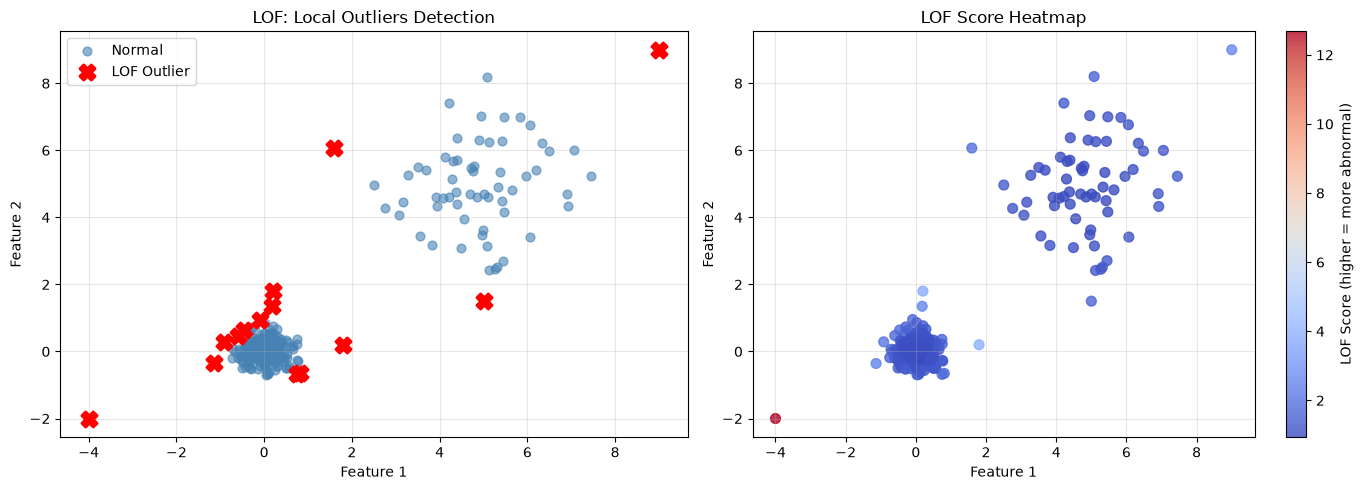

In [5]:
# Visualize LOF results and anomaly scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: normal points vs detected outliers
normal = df[~df["is_outlier"]]
outliers = df[df["is_outlier"]]
axes[0].scatter(normal["feature1"], normal["feature2"], color="steelblue", alpha=0.6, s=40, label="Normal")
axes[0].scatter(outliers["feature1"], outliers["feature2"], color="red", marker="X", s=120, linewidths=2, label="LOF Outlier", zorder=5)
axes[0].set_title("LOF: Local Outliers Detection")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right plot: all points colored by LOF score
scatter = axes[1].scatter(df["feature1"], df["feature2"], c=df["lof_score"], cmap="coolwarm", s=50, alpha=0.8)
plt.colorbar(scatter, ax=axes[1], label="LOF Score (higher = more abnormal)")
axes[1].set_title("LOF Score Heatmap")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
#  Experiment - try different n_neighbors values
for k in [5, 20, 50]:
    temp_lof = LocalOutlierFactor(n_neighbors=k, contamination=0.05)
    temp_labels = temp_lof.fit_predict(X_scaled)
    count = (temp_labels == -1).sum()
    print(f"n_neighbors={k}: detected {count} outliers")

# Question: With k=5 do you get more false alarms inside the sparse cluster?
# Question: With k=50 do the two local outliers near (0,0) disappear? Why?

n_neighbors=5: detected 14 outliers
n_neighbors=20: detected 14 outliers
n_neighbors=50: detected 14 outliers
